# HTTP service: image or short video in, ranked candidates out

## 0. Settings, packages, mount Drive

In [1]:
!pip -q install ultralytics onnxruntime-gpu fastapi uvicorn python-multipart

In [2]:
DRIVE_PROJECT = '/content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial'
# the same models and pipeline as integration.ipynb (run of 16 Nov)
PIPELINE_PY = '04_Integration/2026-11-16_Pipeline_v1/pipeline.py'
CLS_DIR     = '02_Classification/Export/2026-10-31_ClsResNet18_s43_v1'
DET_WEIGHTS = '03_Detection/2026-11-04_P08_Baseline/YOLO11n_Joint_StrongerAug/weights/best.pt'
DET_CONF, DET_IOU, DET_IMGSZ = 0.25, 0.7, 640          # conf 0.25 is the Ultralytics default, not chosen on val
SEG_WEIGHTS = '04_Segmentation/seg/yolo11n_seg_1280/weights/last.pt'
SEG_BACKEND, SEG = 'yolo-seg', dict(conf=0.25, imgsz=1280, match_iou=0.3)
ALTITUDE_M, HFOV_DEG = None, None                      # sizes in pixels unless both are set

PORT = 8000
MAX_VIDEO_S, VIDEO_FPS, MAX_UPLOAD_MB = 10.0, 2.0, 200   # short video: <= 10 s, analysed at 2 frames per second
EXAMPLE_FRAMES = '04_Segmentation/seg/yolo_dataset/images/val'   # frames for the example requests

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Load the pipeline and output folder

In [3]:
import os, re, sys, json, time, shutil
from pathlib import Path
import numpy as np, cv2, torch

ROOT = Path(DRIVE_PROJECT)
P = lambda x: None if x is None else (Path(x) if str(x).startswith('/') else ROOT / x)
for name, p in (('pipeline.py', P(PIPELINE_PY)), ('classifier model.onnx', P(CLS_DIR) / 'model.onnx'),
                ('detector', P(DET_WEIGHTS)), ('segmentation', P(SEG_WEIGHTS))):
    if not p.is_file(): raise FileNotFoundError(f'{name} not found: {p} (set the path in section 0)')

TODAY = time.strftime('%Y-%m-%d')
SVC_DIR = ROOT / '04_Integration/Service'; SVC_DIR.mkdir(parents=True, exist_ok=True)
VERSION = max([int(m.group(1)) for f in os.listdir(SVC_DIR) if (m := re.fullmatch(rf'{TODAY}_Service_v(\d+)', f))], default=0) + 1
OUT = SVC_DIR / f'{TODAY}_Service_v{VERSION}'; (OUT / 'results').mkdir(parents=True)
shutil.copy2(P(PIPELINE_PY), OUT / 'pipeline.py')          # the service folder is self-contained

sys.dont_write_bytecode = True
for d in (str(P(CLS_DIR)), str(OUT)):
    if d not in sys.path: sys.path.insert(0, d)
for m in ('pipeline', 'classify', 'app'): sys.modules.pop(m, None)
import pipeline as pl
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
pipe = pl.Pipeline(P(DET_WEIGHTS), P(CLS_DIR) / 'model.onnx', det_conf=DET_CONF, det_iou=DET_IOU, det_imgsz=DET_IMGSZ,
                   seg_weights=P(SEG_WEIGHTS), seg_backend=SEG_BACKEND, seg_conf=SEG['conf'], seg_imgsz=SEG['imgsz'],
                   seg_match_iou=SEG['match_iou'], device=DEVICE)
pipe.analyze(np.zeros((720, 1280, 3), np.uint8))           # warm-up
print('pipeline loaded on', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU', '| output:', OUT.relative_to(ROOT))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
pipeline loaded on Tesla T4 | output: 04_Integration/Service/2026-11-16_Service_v1


## 2. Service code (`app.py`)

In [4]:
APP_SRC = r"""# AI251P HTTP service: image or short video in -> annotated image/video + JSON of candidates ranked by confidence.
# Candidates are suggestions; a human operator confirms or rejects each one (POST /confirm/{request_id}).
#
#   GET  /health                          models and settings
#   POST /analyze   (multipart "file")    image (jpg/png/bmp/webp) or short video (mp4/mov/avi/mkv)
#        query: include_image=false (base64 annotated jpg in the JSON), top_k=None (keep only the k best)
#   GET  /results/{request_id}/{name}     annotated.jpg | annotated.mp4 | response.json | decisions.jsonl
#   POST /confirm/{request_id}            {"candidate_id": "c001", "decision": "confirmed"|"rejected", "operator": "...", "note": "..."}
import json, time, uuid, base64, threading, datetime
from pathlib import Path
from typing import Literal, Optional
import numpy as np, cv2
from fastapi import FastAPI, UploadFile, File, HTTPException, Query
from fastapi.responses import FileResponse
from pydantic import BaseModel

IMAGE_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
VIDEO_EXT = {'.mp4', '.mov', '.avi', '.mkv'}
RESULT_FILES = {'annotated.jpg', 'annotated.mp4', 'response.json', 'decisions.jsonl'}
NOTE = ('Candidates are suggestions ranked by confidence (highest first). They are not decisions: '
        'a human operator confirms or rejects each one with POST /confirm/{request_id}.')

def rle(bitmap):
    # row-major run lengths of a 0/1 bitmap, starting with a run of zeros
    flat = np.asarray(bitmap, np.uint8).reshape(-1)
    if flat.size == 0: return []
    change = np.flatnonzero(np.diff(flat)) + 1
    runs = np.diff(np.r_[0, change, flat.size]).tolist()
    return ([0] + runs) if flat[0] == 1 else runs

def to_candidate(o, frame=None, t_s=None):
    m = o.get('mask')
    mask = None if m is None else {'origin_xy': [int(m['origin_xy'][0]), int(m['origin_xy'][1])],
                                   'size_hw': [int(m['bitmap'].shape[0]), int(m['bitmap'].shape[1])],
                                   'rle_row_major': rle(m['bitmap'])}
    size = {k: (None if v is None else (v if isinstance(v, str) else float(v))) for k, v in o['size'].items()}
    c = {'class': o['class'], 'confidence': round(float(o['confidence']), 5), 'box_xywh': [round(float(v), 2) for v in o['box_xywh']],
         'mask': mask, 'size': size, 'detector_class': o.get('det_class'), 'detector_confidence': round(float(o.get('det_confidence', 0)), 5),
         'status': 'pending_human_confirmation'}
    if frame is not None: c |= {'frame': int(frame), 'time_s': round(float(t_s), 3)}
    return c

def rank(cands, top_k=None):
    cands = sorted(cands, key=lambda c: -c['confidence'])
    for i, c in enumerate(cands, 1): c['rank'] = i; c['candidate_id'] = f'c{i:03d}'
    return cands[:top_k] if top_k else cands

def create_app(pipe, draw, out_dir, max_video_s=10.0, video_fps=2.0, max_upload_mb=200, altitude_m=None, hfov_deg=None, info=None):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    app = FastAPI(title='AI251P aerial candidates service', version='1.0')
    lock = threading.Lock()                       # one pipeline call at a time (one GPU)

    def annotate(img_rgb, res, ranks):
        vis = draw(img_rgb, res)
        for o, r in zip(res['objects'], ranks):
            if r is None: continue
            x, y = int(o['box_xywh'][0]), int(o['box_xywh'][1] + o['box_xywh'][3])
            cv2.putText(vis, f'#{r}', (x, min(vis.shape[0] - 2, y + 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 1, cv2.LINE_AA)
        return vis

    @app.get('/health')
    def health():
        return {'status': 'ok', 'max_video_s': max_video_s, 'video_fps': video_fps, 'max_upload_mb': max_upload_mb, **(info or {})}

    @app.post('/analyze')
    async def analyze(file: UploadFile = File(...), include_image: bool = Query(False), top_k: Optional[int] = Query(None, ge=1)):
        t0 = time.perf_counter()
        data = await file.read()
        if len(data) > max_upload_mb * 1e6: raise HTTPException(413, f'file larger than {max_upload_mb} MB')
        name = Path(file.filename or 'upload').name; ext = Path(name).suffix.lower()
        if ext not in IMAGE_EXT | VIDEO_EXT:
            raise HTTPException(415, f'unsupported file type {ext!r}; images {sorted(IMAGE_EXT)}, videos {sorted(VIDEO_EXT)}')
        rid = datetime.datetime.now(datetime.timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:6]
        d = out_dir / rid; d.mkdir()
        if ext in IMAGE_EXT:
            bgr = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
            if bgr is None: raise HTTPException(400, 'could not decode the image')
            rgb = np.ascontiguousarray(bgr[..., ::-1])
            with lock: res = pipe.analyze(rgb, altitude_m=altitude_m, hfov_deg=hfov_deg)
            cands = rank([to_candidate(o) for o in res['objects']], top_k)
            order = sorted(range(len(res['objects'])), key=lambda i: -res['objects'][i]['confidence'])
            ranks = [None] * len(order)
            for r, i in enumerate(order, 1): ranks[i] = r if (not top_k or r <= top_k) else None
            vis = annotate(rgb, res, ranks)
            cv2.imwrite(str(d / 'annotated.jpg'), vis[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, 90])
            inp = {'type': 'image', 'filename': name, 'height': rgb.shape[0], 'width': rgb.shape[1]}
            timing = {'pipeline_ms': res['timing_ms']}
            urls = {'annotated_image_url': f'/results/{rid}/annotated.jpg', 'annotated_video_url': None}
        else:
            src = d / ('input' + ext); src.write_bytes(data)
            cap = cv2.VideoCapture(str(src))
            if not cap.isOpened(): raise HTTPException(400, 'could not open the video')
            fps = cap.get(cv2.CAP_PROP_FPS) or 0; n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
            if fps <= 0: cap.release(); raise HTTPException(400, 'video has no frame rate')
            dur = n / fps
            if dur > max_video_s: cap.release(); raise HTTPException(413, f'video is {dur:.1f} s; the limit is {max_video_s} s')
            step = max(1, round(fps / video_fps)); k = 0; cands = []; frames = []; per_frame = []
            writer = None
            while True:
                ok, bgr = cap.read()
                if not ok: break
                if k % step == 0:
                    rgb = np.ascontiguousarray(bgr[..., ::-1])
                    with lock: res = pipe.analyze(rgb, altitude_m=altitude_m, hfov_deg=hfov_deg)
                    cands += [to_candidate(o, k, k / fps) for o in res['objects']]
                    frames.append((k, rgb, res)); per_frame.append(res['timing_ms']['total'])
                k += 1
            cap.release(); src.unlink()
            cands = rank(cands, top_k)
            keep = {(c['frame'], c['box_xywh'][0], c['box_xywh'][1]): c['rank'] for c in cands}
            best_frame = cands[0]['frame'] if cands else (frames[0][0] if frames else None)
            for fk, rgb, res in frames:
                ranks = [keep.get((fk, round(float(o['box_xywh'][0]), 2), round(float(o['box_xywh'][1]), 2))) for o in res['objects']]
                vis = annotate(rgb, res, ranks)
                if writer is None:
                    writer = cv2.VideoWriter(str(d / 'annotated.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), video_fps, (vis.shape[1], vis.shape[0]))
                writer.write(vis[..., ::-1])
                if fk == best_frame: cv2.imwrite(str(d / 'annotated.jpg'), vis[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, 90])
            if writer is not None: writer.release()
            h, w = (frames[0][1].shape[:2] if frames else (0, 0))
            inp = {'type': 'video', 'filename': name, 'height': h, 'width': w, 'fps': round(fps, 3), 'duration_s': round(dur, 3),
                   'frames_total': n, 'frames_analyzed': len(frames), 'sampled_every_n_frames': step,
                   'annotated_image_frame': best_frame}
            timing = {'pipeline_ms_per_frame_mean': round(float(np.mean(per_frame)), 2) if per_frame else None}
            urls = {'annotated_image_url': f'/results/{rid}/annotated.jpg' if frames else None,
                    'annotated_video_url': f'/results/{rid}/annotated.mp4' if frames else None}
        timing['request_ms'] = round((time.perf_counter() - t0) * 1e3, 2)
        resp = {'request_id': rid, 'input': inp, 'n_candidates': len(cands), 'ranked_by': 'confidence (classifier), descending',
                'note': NOTE, 'candidates': cands, **urls, 'timing': timing}
        (d / 'response.json').write_text(json.dumps(resp, indent=1))
        if include_image and urls['annotated_image_url']:
            resp['annotated_image_jpg_base64'] = base64.b64encode((d / 'annotated.jpg').read_bytes()).decode()
        return resp

    @app.get('/results/{rid}/{name}')
    def result(rid: str, name: str):
        if name not in RESULT_FILES or '/' in rid or '..' in rid: raise HTTPException(404, 'not found')
        p = out_dir / rid / name
        if not p.is_file(): raise HTTPException(404, 'not found')
        return FileResponse(p)

    class Decision(BaseModel):
        candidate_id: str
        decision: Literal['confirmed', 'rejected']
        operator: str = ''
        note: str = ''

    @app.post('/confirm/{rid}')
    def confirm(rid: str, dec: Decision):
        if '/' in rid or '..' in rid: raise HTTPException(404, 'unknown request_id')
        p = out_dir / rid / 'response.json'
        if not p.is_file(): raise HTTPException(404, 'unknown request_id')
        with lock:
            resp = json.loads(p.read_text())
            c = next((c for c in resp['candidates'] if c['candidate_id'] == dec.candidate_id), None)
            if c is None: raise HTTPException(404, f'unknown candidate_id {dec.candidate_id}')
            c['status'] = dec.decision; c['decided_by'] = dec.operator
            c['decided_at_utc'] = datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds')
            p.write_text(json.dumps(resp, indent=1))
            with open(out_dir / rid / 'decisions.jsonl', 'a') as f: f.write(json.dumps({**dec.model_dump(), 'at_utc': c['decided_at_utc']}) + '\n')
        counts = {s: sum(x['status'] == s for x in resp['candidates']) for s in ('pending_human_confirmation', 'confirmed', 'rejected')}
        return {'request_id': rid, 'candidate_id': dec.candidate_id, 'status': c['status'], 'counts': counts}

    return app
"""

(OUT / 'app.py').write_text(APP_SRC)
import app as svc
rel = lambda p: Path(p).relative_to(ROOT).as_posix()
INFO = {'detector': rel(P(DET_WEIGHTS)), 'detector_conf': DET_CONF, 'detector_conf_note': 'Ultralytics default, not chosen on val',
        'classifier': rel(P(CLS_DIR)), 'segmentation': rel(P(SEG_WEIGHTS)), 'device': DEVICE}
APP = svc.create_app(pipe, pl.draw, OUT / 'results', max_video_s=MAX_VIDEO_S, video_fps=VIDEO_FPS,
                     max_upload_mb=MAX_UPLOAD_MB, altitude_m=ALTITUDE_M, hfov_deg=HFOV_DEG, info=INFO)
print('routes:', [r.path for r in APP.routes if hasattr(r, 'methods')])

routes: ['/openapi.json', '/docs', '/docs/oauth2-redirect', '/redoc', '/health', '/analyze', '/results/{rid}/{name}', '/confirm/{rid}']


## 3. Start the service

In [5]:
import threading, uvicorn, requests
server = uvicorn.Server(uvicorn.Config(APP, host='0.0.0.0', port=PORT, log_level='warning'))
threading.Thread(target=server.run, daemon=True).start()
BASE = f'http://localhost:{PORT}'
for _ in range(60):
    try:
        if requests.get(BASE + '/health', timeout=1).ok: break
    except requests.ConnectionError: time.sleep(0.5)
print(json.dumps(requests.get(BASE + '/health').json(), indent=1))
try:   # optional: a browser URL for this Colab runtime (works only for you, while the runtime is alive)
    from google.colab.output import eval_js
    print('browser URL (docs at /docs):', eval_js(f'google.colab.kernel.proxyPort({PORT})'))
except Exception as e: print('no browser URL:', e)

{
 "status": "ok",
 "max_video_s": 10.0,
 "video_fps": 2.0,
 "max_upload_mb": 200,
 "detector": "03_Detection/2026-11-04_P08_Baseline/YOLO11n_Joint_StrongerAug/weights/best.pt",
 "detector_conf": 0.25,
 "detector_conf_note": "Ultralytics default, not chosen on val",
 "classifier": "02_Classification/Export/2026-10-31_ClsResNet18_s43_v1",
 "segmentation": "04_Segmentation/seg/yolo11n_seg_1280/weights/last.pt",
 "device": "cuda"
}
browser URL (docs at /docs): https://8000-gpu-t4-s-usw4b0-v3ce43fy775e-b.us-west4.prod.r.colab.dev


## 4. Example request: image

request 20261116T195629Z_24cf11: 26 candidates, {'pipeline_ms': {'detect': 65.65010299999585, 'classify': 294.3110790000105, 'segment': 274.6798130000343, 'size': 7.9051009999489, 'total': 642.6176960000021}, 'request_ms': 785.24}
# 1 c001 car                      conf 0.971  box [241.28, 984.74, 27.12, 38.22]  mask yes  length 27 px  pending_human_confirmation
# 2 c002 car                      conf 0.954  box [237.43, 548.47, 27.5, 29.49]  mask yes  length 20 px  pending_human_confirmation
# 3 c003 car                      conf 0.954  box [226.25, 588.5, 29.27, 29.51]  mask yes  length 19 px  pending_human_confirmation
# 4 c004 car                      conf 0.954  box [271.89, 968.27, 31.14, 34.74]  mask yes  length 28 px  pending_human_confirmation
# 5 c005 car                      conf 0.949  box [272.03, 747.52, 28.15, 31.01]  mask yes  length 24 px  pending_human_confirmation
# 6 c006 car                      conf 0.948  box [64.47, 493.82, 28.42, 26.68]  mask yes  length 19 px  p

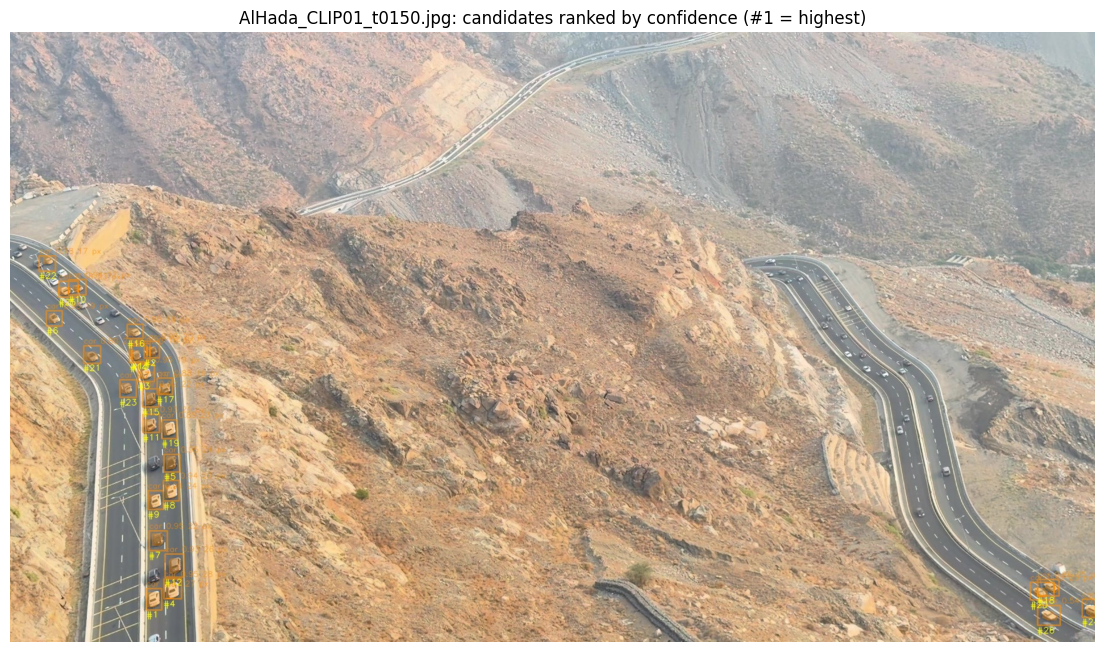

In [6]:
import matplotlib.pyplot as plt
frames = sorted(p for p in P(EXAMPLE_FRAMES).rglob('*') if p.suffix.lower() in ('.jpg', '.jpeg', '.png'))
IMG = frames[len(frames) // 2]
with open(IMG, 'rb') as f:
    r = requests.post(BASE + '/analyze', files={'file': (IMG.name, f, 'image/jpeg')}, params={'include_image': 'false'})
r.raise_for_status(); R_IMG = r.json()
print(f"request {R_IMG['request_id']}: {R_IMG['n_candidates']} candidates, {R_IMG['timing']}")
for c in R_IMG['candidates'][:10]:
    print(f"#{c['rank']:>2} {c['candidate_id']} {c['class']:<24} conf {c['confidence']:.3f}  box {c['box_xywh']}  "
          f"mask {'yes' if c['mask'] else 'no '}  length {c['size']['length_px']:.0f} px  {c['status']}")
ann = requests.get(BASE + R_IMG['annotated_image_url']).content
plt.figure(figsize=(14, 8)); plt.imshow(cv2.imdecode(np.frombuffer(ann, np.uint8), cv2.IMREAD_COLOR)[..., ::-1]); plt.axis('off')
plt.title(f"{IMG.name}: candidates ranked by confidence (#1 = highest)"); plt.show()

## 5. Example request: short video

In [7]:
VID = Path('/content/example_clip.mp4')
clip = frames[:20]                                          # 20 consecutive frames at 5 fps = 4 s
first = cv2.imread(str(clip[0])); h, w = first.shape[:2]
vw = cv2.VideoWriter(str(VID), cv2.VideoWriter_fourcc(*'mp4v'), 5, (w, h))
for f in clip: vw.write(cv2.resize(cv2.imread(str(f)), (w, h)))
vw.release()
with open(VID, 'rb') as f:
    r = requests.post(BASE + '/analyze', files={'file': (VID.name, f, 'video/mp4')}, params={'top_k': 50})
r.raise_for_status(); R_VID = r.json()
print(json.dumps(R_VID['input'], indent=1)); print(R_VID['timing'])
for c in R_VID['candidates'][:10]:
    print(f"#{c['rank']:>2} {c['candidate_id']} frame {c['frame']:>3} t={c['time_s']:.1f}s {c['class']:<24} conf {c['confidence']:.3f}")
print('annotated video:', R_VID['annotated_video_url'], '| key frame:', R_VID['annotated_image_url'])

{
 "type": "video",
 "filename": "example_clip.mp4",
 "height": 1080,
 "width": 1920,
 "fps": 5.0,
 "duration_s": 4.0,
 "frames_total": 20,
 "frames_analyzed": 10,
 "sampled_every_n_frames": 2,
 "annotated_image_frame": 18
}
{'pipeline_ms_per_frame_mean': 156.18, 'request_ms': 2401.1}
# 1 c001 frame  18 t=3.6s car                      conf 0.977
# 2 c002 frame   0 t=0.0s car                      conf 0.976
# 3 c003 frame  18 t=3.6s car                      conf 0.976
# 4 c004 frame  10 t=2.0s car                      conf 0.973
# 5 c005 frame   2 t=0.4s car                      conf 0.973
# 6 c006 frame   4 t=0.8s car                      conf 0.972
# 7 c007 frame  10 t=2.0s car                      conf 0.972
# 8 c008 frame   4 t=0.8s car                      conf 0.969
# 9 c009 frame   6 t=1.2s car                      conf 0.966
#10 c010 frame  16 t=3.2s car                      conf 0.966
annotated video: /results/20261116T195718Z_87d10b/annotated.mp4 | key frame: /results/20261116

## 6. Human confirmation and acceptance check

In [8]:
# an operator confirms the top candidate and rejects the second one
for cid, dec in (('c001', 'confirmed'), ('c002', 'rejected')):
    if R_IMG['n_candidates'] >= int(cid[1:]):
        print(requests.post(BASE + f"/confirm/{R_IMG['request_id']}", json={'candidate_id': cid, 'decision': dec, 'operator': 'example'}).json())

def check(name, ok):
    print(('PASS ' if ok else 'FAIL ') + name); assert ok, name
for R in (R_IMG, R_VID):
    C = R['candidates']; conf = [c['confidence'] for c in C]
    check(f"{R['input']['type']}: candidates ranked by confidence (descending)", conf == sorted(conf, reverse=True))
    check(f"{R['input']['type']}: ranks are 1..n", [c['rank'] for c in C] == list(range(1, len(C) + 1)))
    check(f"{R['input']['type']}: every candidate has class, confidence, box, mask, size",
          all(all(k in c for k in ('class', 'confidence', 'box_xywh', 'mask', 'size')) for c in C))
    check(f"{R['input']['type']}: candidates start as pending human confirmation",
          all(c['status'] == 'pending_human_confirmation' for c in C))
saved = json.loads((OUT / 'results' / R_IMG['request_id'] / 'response.json').read_text())
check('confirmation is stored with the request', R_IMG['n_candidates'] == 0 or saved['candidates'][0]['status'] == 'confirmed')

{'request_id': '20261116T195629Z_24cf11', 'candidate_id': 'c001', 'status': 'confirmed', 'counts': {'pending_human_confirmation': 25, 'confirmed': 1, 'rejected': 0}}
{'request_id': '20261116T195629Z_24cf11', 'candidate_id': 'c002', 'status': 'rejected', 'counts': {'pending_human_confirmation': 24, 'confirmed': 1, 'rejected': 1}}
PASS image: candidates ranked by confidence (descending)
PASS image: ranks are 1..n
PASS image: every candidate has class, confidence, box, mask, size
PASS image: candidates start as pending human confirmation
PASS video: candidates ranked by confidence (descending)
PASS video: ranks are 1..n
PASS video: every candidate has class, confidence, box, mask, size
PASS video: candidates start as pending human confirmation
PASS confirmation is stored with the request


## 7. Example request file and stop

In [9]:
EXAMPLE = f"""# Example requests: AI251P aerial candidates service

Start the service with `notebooks/integration/service.ipynb` (sections 0-3). Base URL inside the runtime: `{BASE}`.

## Image
```bash
curl -X POST -F "file=@frame.jpg" "{BASE}/analyze"
curl -o annotated.jpg "{BASE}/results/<request_id>/annotated.jpg"
```

## Short video (<= {MAX_VIDEO_S:.0f} s, analysed at {VIDEO_FPS:g} frames per second)
```bash
curl -X POST -F "file=@clip.mp4" "{BASE}/analyze?top_k=50"
curl -o annotated.mp4 "{BASE}/results/<request_id>/annotated.mp4"
```

## Human confirmation
```bash
curl -X POST -H "Content-Type: application/json" \\
     -d '{{"candidate_id": "c001", "decision": "confirmed", "operator": "your name"}}' \\
     "{BASE}/confirm/<request_id>"
```

## Python
```python
import requests
r = requests.post("{BASE}/analyze", files={{"file": open("frame.jpg", "rb")}})
for c in r.json()["candidates"]:      # ranked by confidence, highest first
    print(c["rank"], c["class"], c["confidence"], c["box_xywh"], c["size"]["length_px"], c["status"])
```

## Response (image, first candidate shown)
```json
{json.dumps({k: (v[:1] if k == 'candidates' else v) for k, v in R_IMG.items()}, indent=1)[:3000]}
```

Mask format: `origin_xy` (top-left of the box in the image), `size_hw`, and `rle_row_major` (run lengths of 0/1 inside the box, row by row, starting with zeros).
Candidates are suggestions; the operator confirms or rejects each one. Detector conf {DET_CONF} is the Ultralytics default, not chosen on val.
"""
(OUT / 'EXAMPLE_REQUEST.md').write_text(EXAMPLE)
shutil.copy2(VID, OUT / 'example_clip.mp4'); shutil.copy2(IMG, OUT / ('example_' + IMG.name))
print('saved in', OUT.relative_to(ROOT), ':', sorted(p.name for p in OUT.iterdir()))
# server.should_exit = True     # uncomment to stop the service

saved in 04_Integration/Service/2026-11-16_Service_v1 : ['EXAMPLE_REQUEST.md', 'app.py', 'example_AlHada_CLIP01_t0150.jpg', 'example_clip.mp4', 'pipeline.py', 'results']
